# Player bounding

Load 20 frames from a SportsMOT training sequence for player-detection work.

In [1]:
from io import BytesIO
from pathlib import Path
import tarfile

from PIL import Image

archive_candidates = [
    Path(r"C:\Users\Dishi\OneDrive - University of Florida\UF!!!!\NvidaXBasketball\DSI-NVIDIA-Basketball-Shot-Analysis-Project\sportsmot_download\dataset\train.tar"),
    Path(r"C:\Users\Dishi\OneDrive - University of Florida\UF!!!!\NvidaXBasketball\DSI-NVIDIA-Basketball-Shot-Analysis-Project\sportsmot_download\dataset\train.tar"),
]
archive = next((path for path in archive_candidates if path.exists()), None)

if archive is None:
    raise FileNotFoundError("Could not find data/sportsmot_download/dataset/train.tar")

sequence = "train/v_-6Os86HzwCs_c001"

with tarfile.open(archive, "r") as tar:
    selected = sorted(
        (member for member in tar.getmembers()
         if member.isfile()
         and member.name.startswith(sequence + "/img1/")
         and member.name.endswith(".jpg")
         and not member.name.rsplit("/", 1)[-1].startswith("._")),
        key=lambda member: member.name,
    )[:20]

    images = [
        Image.open(BytesIO(tar.extractfile(member).read())).convert("RGB")
        for member in selected
    ]

print(f"Loaded {len(images)} frames from {sequence}")
print(f"First frame: {selected[0].name}")

Loaded 20 frames from train/v_-6Os86HzwCs_c001
First frame: train/v_-6Os86HzwCs_c001/img1/000001.jpg


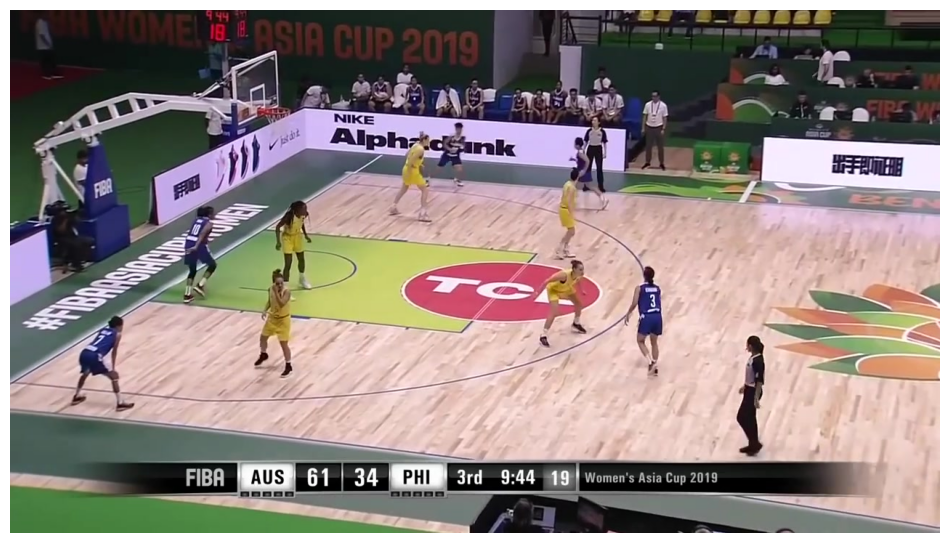

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))
plt.imshow(images[0])
plt.axis("off")
plt.show()

work here

In [3]:
from ultralytics import YOLO
print("it works")

it works



0: 736x1280 11 persons, 941.6ms
Speed: 9.9ms preprocess, 941.6ms inference, 2.3ms postprocess per image at shape (1, 3, 736, 1280)


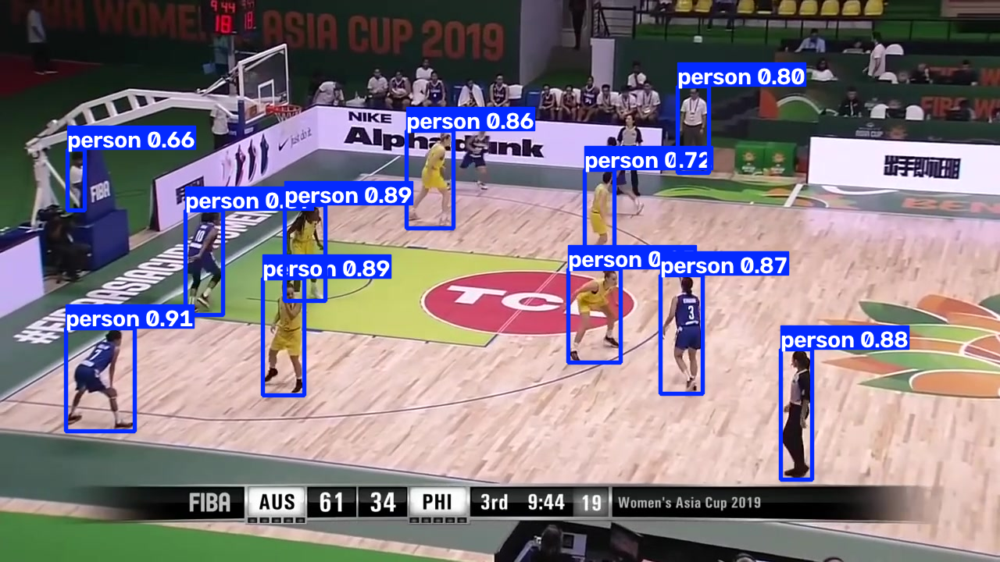

In [4]:
import numpy as np
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

with tarfile.open(archive, "r") as tar:
    names = sorted(m.name for m in tar.getmembers()
                   if m.name.startswith(sequence + "/img1/")
                   and m.name.endswith(".jpg")
                   and "/._" not in m.name)
    data = tar.extractfile(names[0]).read()

img = np.array(Image.open(BytesIO(data)).convert("RGB"))[..., ::-1]

results = model(img, classes=[0], conf=0.65, imgsz=1280) 
Image.fromarray(results[0].plot()[..., ::-1])

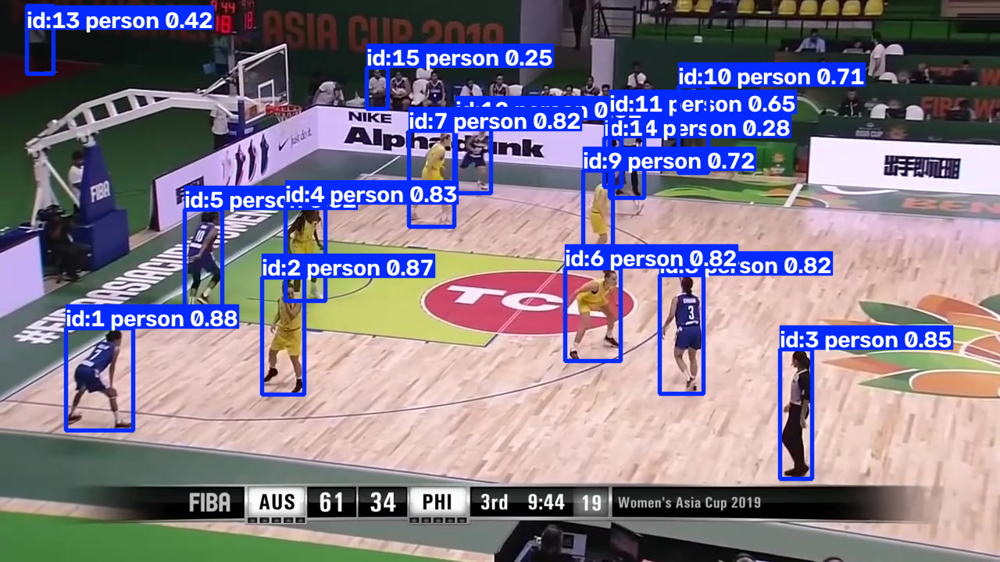

In [5]:
import numpy as np
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

with tarfile.open(archive, "r") as tar:
    names = sorted(m.name for m in tar.getmembers()
                   if m.name.startswith(sequence + "/img1/")
                   and m.name.endswith(".jpg")
                   and "/._" not in m.name)
    frames = [np.array(Image.open(BytesIO(tar.extractfile(n).read())).convert("RGB"))[..., ::-1]
              for n in names[:20]]

annotated = []
for frame in frames:
    r = model.track(frame, classes=[0], persist=True, tracker="bytetrack.yaml", verbose=False)[0]
    annotated.append(Image.fromarray(r.plot()[..., ::-1]))

annotated[0]

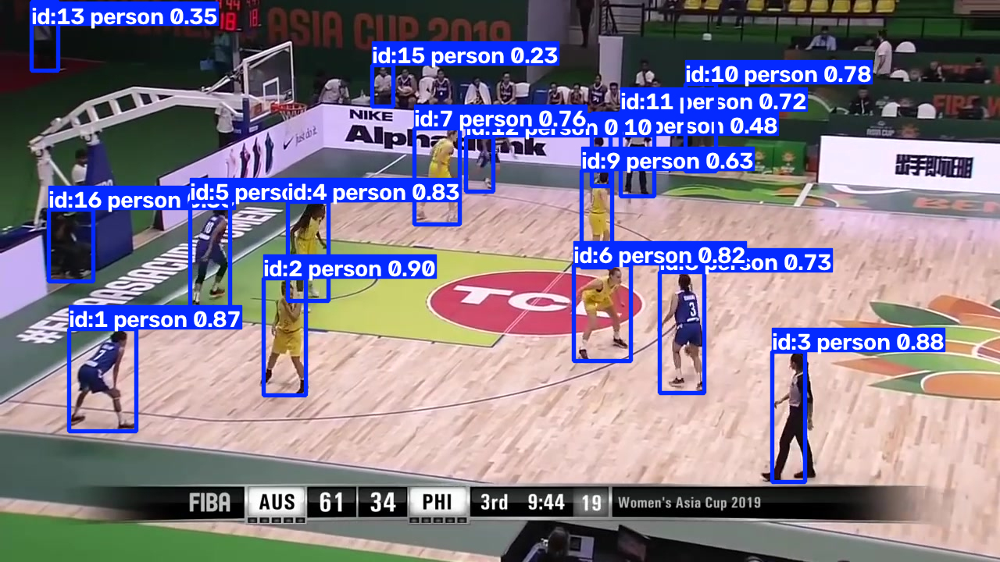

In [6]:
annotated[3]

I tried to create  a border around the court and tracked the people within that border. However, it is still detecting the referees. 

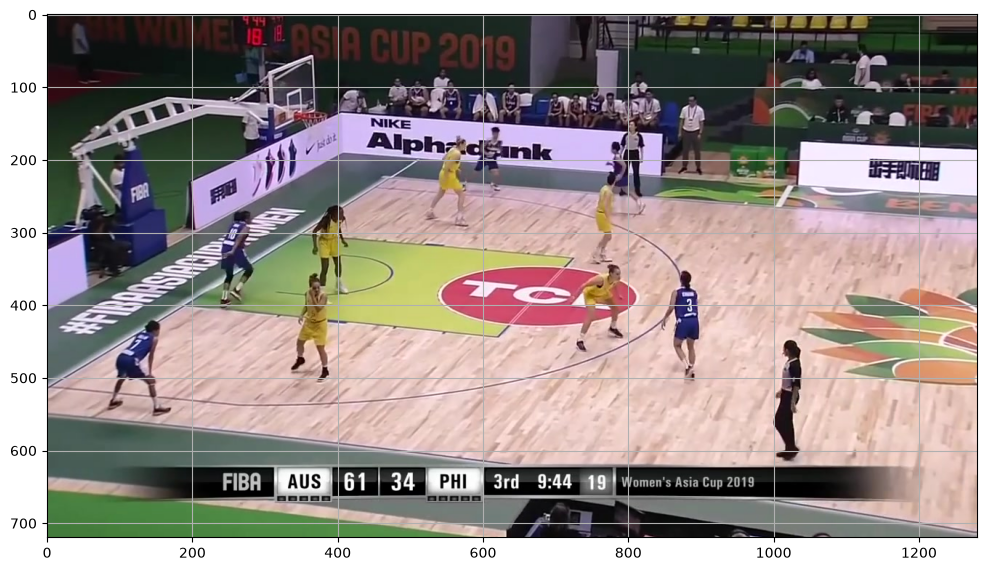

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))
plt.imshow(frames[0][..., ::-1])
plt.grid(True)
plt.show()

In [8]:
import cv2

court = np.array([[0, 570], [1280, 650], [1280, 235], [1000, 238],
                  [640, 208], [430, 185], [200, 295], [0, 470]], dtype=np.int32)

def on_court(box):
    x1, y1, x2, y2 = box
    feet = (float((x1 + x2) / 2), float(y2))
    return cv2.pointPolygonTest(court, feet, False) >= 0

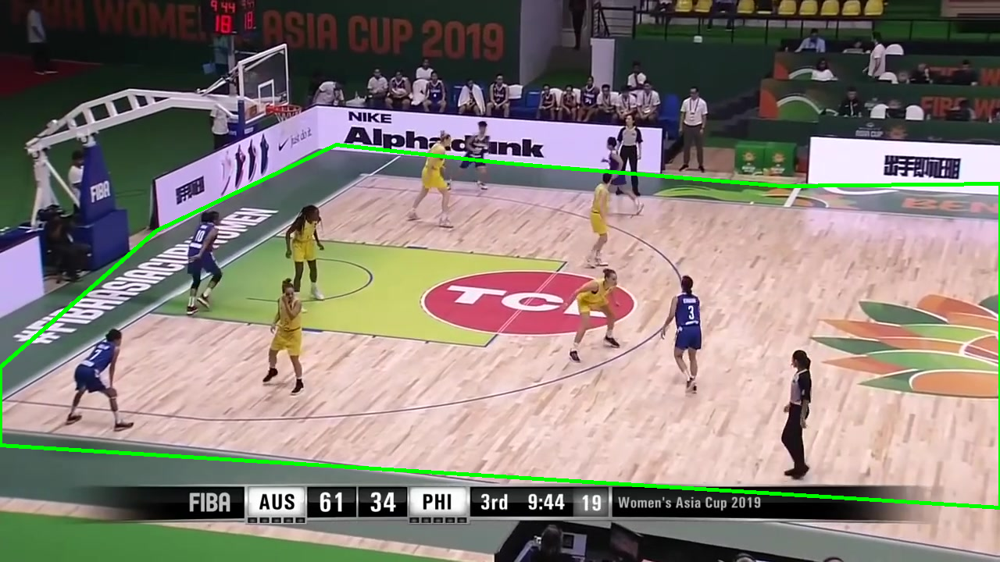

In [9]:
check = frames[0].copy()
cv2.polylines(check, [court], True, (0, 255, 0), 3)
Image.fromarray(check[..., ::-1])

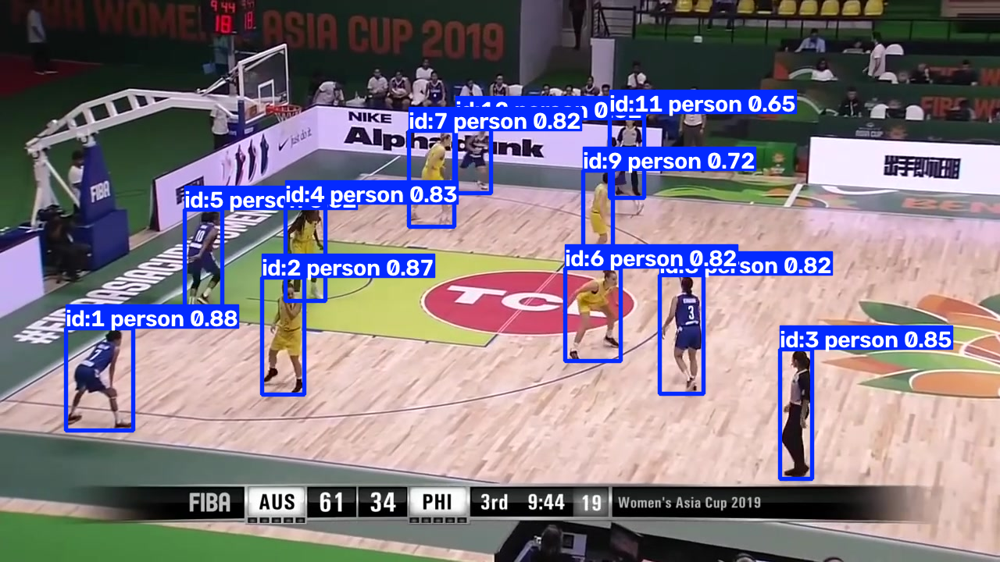

In [10]:
model = YOLO("yolov8m.pt")

annotated = []
for frame in frames:
    r = model.track(frame, classes=[0], conf=0.3, persist=True,
                    tracker="bytetrack.yaml", verbose=False)[0]
    keep = np.array([on_court(b) for b in r.boxes.xyxy.cpu().numpy()], dtype=bool)
    r = r[keep]
    annotated.append(Image.fromarray(r.plot()[..., ::-1]))

annotated[0]

In [11]:
r = model.predict(frames[0], classes=[0], conf=0.25, verbose=False)[0]
for b in r.boxes.xyxy.cpu().numpy():
    print(b.round(), on_court(b))

[         85         420         171         551] True
[        336         355         390         505] True
[        999         447        1039         614] True
[        366         261         417         386] True
[        237         269         285         403] True
[        724         343         795         463] True
[        523         168         581         291] True
[        844         352         900         504] True
[        746         218         785         343] True
[        868         111         906         221] False
[        781         146         824         254] True
[        583         153         628         247] True
[         34           7          68          94] False
[        773         176         796         240] True
[        469          87         497         139] False


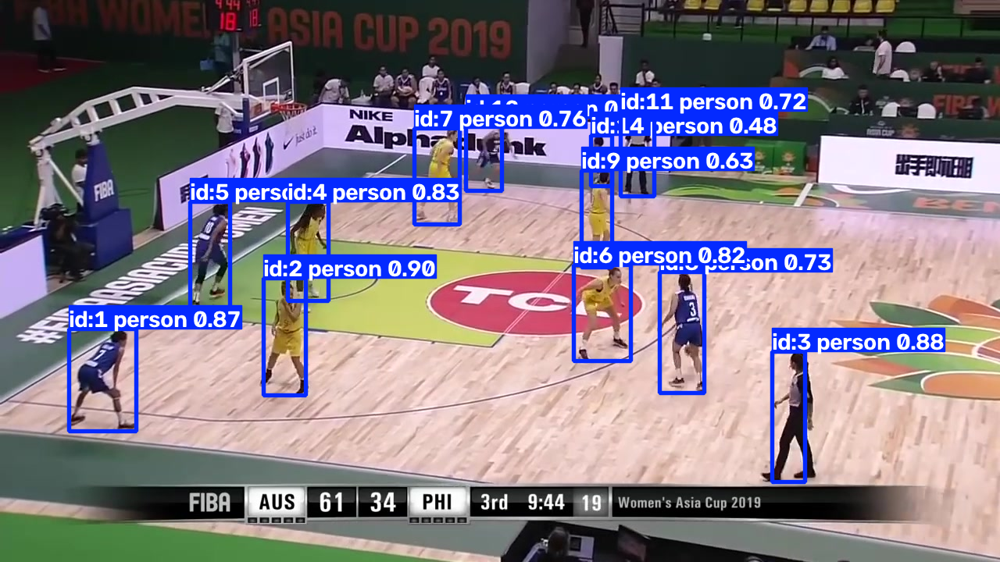

In [12]:
annotated[3]

## Automated court regions
Replaces the hand-drawn `court` polygon. The floor color is found automatically, and each connected floor region gets its own polygon, so the filter follows the camera instead of a fixed pixel shape. Uses `images` (RGB) for color detection and `frames` (BGR) for YOLO.

In [13]:
import cv2
import numpy as np


def estimate_floor_hsv(hsv, sample_rows=(0.35, 1.0), sat_min=40, val_min=60):
    """Automatically estimate the floor color (no hand-picked seeds).

    Looks at the lower part of the frame (where the floor almost always is), ignores
    dark/gray pixels (crowd shadows, black courtside boards, white lines), and takes
    the peak of the hue histogram. Returns the (H, S, V) median of pixels near that peak.
    """
    h, w = hsv.shape[:2]
    region = hsv[int(sample_rows[0] * h):int(sample_rows[1] * h)].reshape(-1, 3)
    colorful = region[(region[:, 1] >= sat_min) & (region[:, 2] >= val_min)]
    if len(colorful) < 500:
        return None
    hist = np.bincount(colorful[:, 0], minlength=180).astype(float)
    # circular smoothing so a floor straddling the hue wrap (reds) still peaks correctly
    k = np.ones(7) / 7
    padded = np.concatenate([hist[-3:], hist, hist[:3]])
    hist_s = np.convolve(padded, k, mode="valid")
    peak = int(np.argmax(hist_s))
    dh = np.minimum(np.abs(colorful[:, 0].astype(int) - peak), 180 - np.abs(colorful[:, 0].astype(int) - peak))
    near = colorful[dh <= 6]
    return tuple(np.median(near, axis=0).astype(int))


def detect_court_regions(frame, hue_tol=12, sat_tol=70, val_tol=80,
                         min_region_frac=0.01, pad_px=12, use_convex=True):
    """Return (list_of_polygons, mask). One polygon per connected floor region.

    Instead of a single convex hull over every floor pixel, each white blob in the floor
    mask gets its own polygon, so empty space between blobs (sideline, bench, crowd) is
    not counted as court. Small blobs (<min_region_frac of the frame) are dropped as noise.
    """
    img = np.array(frame)
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    h, w = hsv.shape[:2]

    floor = estimate_floor_hsv(hsv)
    if floor is None:
        return [], np.zeros((h, w), np.uint8)
    fh, fs, fv = floor

    dh = np.abs(hsv[..., 0].astype(int) - fh)
    dh = np.minimum(dh, 180 - dh)
    mask = ((dh <= hue_tol)
            & (np.abs(hsv[..., 1].astype(int) - fs) <= sat_tol)
            & (np.abs(hsv[..., 2].astype(int) - fv) <= val_tol)).astype(np.uint8) * 255

    # bridge court lines/players inside the floor, then remove speckle
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((25, 25), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((7, 7), np.uint8))

    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    polygons = []
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] < min_region_frac * h * w:
            continue
        ys, xs = np.nonzero(labels == i)
        pts = np.column_stack([xs, ys]).astype(np.int32)
        if use_convex:
            poly = cv2.convexHull(pts)
        else:
            cnts, _ = cv2.findContours((labels == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            poly = max(cnts, key=cv2.contourArea)
        poly = cv2.approxPolyDP(poly, 0.015 * cv2.arcLength(poly, True), True)
        polygons.append(poly)

    # pad each region a little so feet right at the boundary aren't clipped
    if pad_px > 0 and polygons:
        pm = np.zeros((h, w), np.uint8)
        cv2.fillPoly(pm, polygons, 255)
        pm = cv2.dilate(pm, np.ones((2 * pad_px + 1, 2 * pad_px + 1), np.uint8))
        cnts, _ = cv2.findContours(pm, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        polygons = [cv2.approxPolyDP(c, 0.01 * cv2.arcLength(c, True), True) for c in cnts]
    return polygons, mask


def box_in_regions(box, polygons):
    """Feet point must fall inside ANY region. Fails open if no regions were found."""
    if not polygons:
        return True
    x1, y1, x2, y2 = box
    foot = (float((x1 + x2) / 2), float(y2))
    return any(cv2.pointPolygonTest(p, foot, False) >= 0 for p in polygons)


def region_bounding_boxes(polygons):
    """Axis-aligned (x, y, w, h) box around each region, for drawing."""
    return [cv2.boundingRect(p) for p in polygons]


### Visual check 

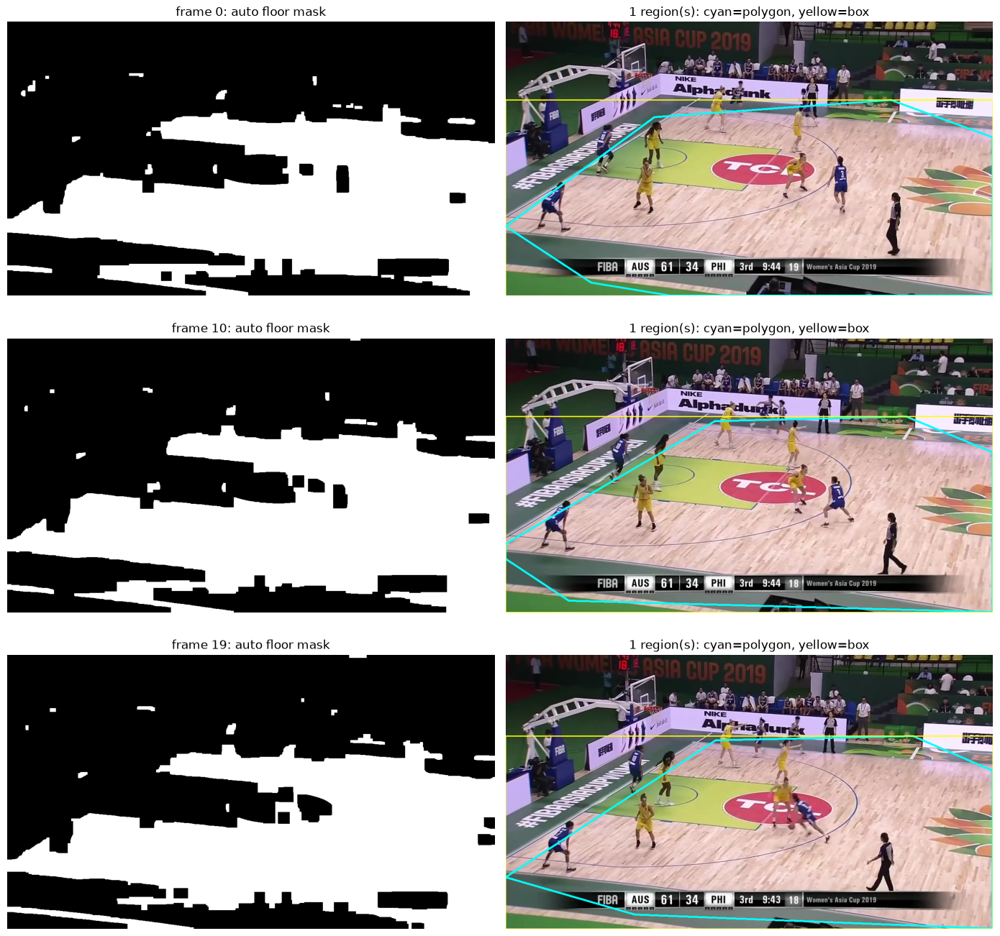

In [18]:
import matplotlib.pyplot as plt

check = [0, len(images)//2, len(images)-1]
fig, axes = plt.subplots(len(check), 2, figsize=(14, 4.5*len(check)))
for row, fi in enumerate(check):
    rgb = np.array(images[fi])
    regions, mask = detect_court_regions(rgb)
    axes[row, 0].imshow(mask, cmap="gray"); axes[row, 0].set_title(f"frame {fi}: auto floor mask")
    out = rgb.copy()
    cv2.polylines(out, regions, True, (0, 255, 255), 3)
    for (x, y, w, h) in region_bounding_boxes(regions):
        cv2.rectangle(out, (x, y), (x+w, y+h), (255, 255, 0), 2)
    axes[row, 1].imshow(out); axes[row, 1].set_title(f"{len(regions)} region(s): cyan=polygon, yellow=box")
    for a in axes[row]: a.axis("off")
plt.tight_layout(); plt.show()

### Track with the automatic filter


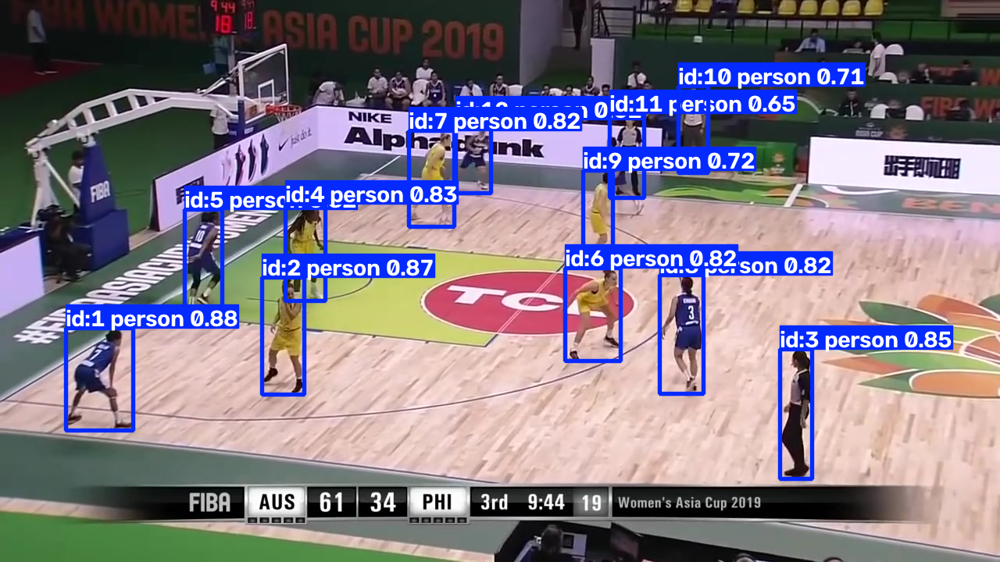

In [15]:
model = YOLO("yolov8m.pt")
court_regions_by_frame = [detect_court_regions(np.array(img))[0] for img in images]

annotated_auto = []
for frame, regions in zip(frames, court_regions_by_frame):
    r = model.track(frame, classes=[0], conf=0.3, persist=True,
                    tracker="bytetrack.yaml", verbose=False)[0]
    keep = np.array([box_in_regions(b, regions) for b in r.boxes.xyxy.cpu().numpy()], dtype=bool)
    r = r[keep]
    annotated_auto.append(Image.fromarray(r.plot()[..., ::-1]))

annotated_auto[0]

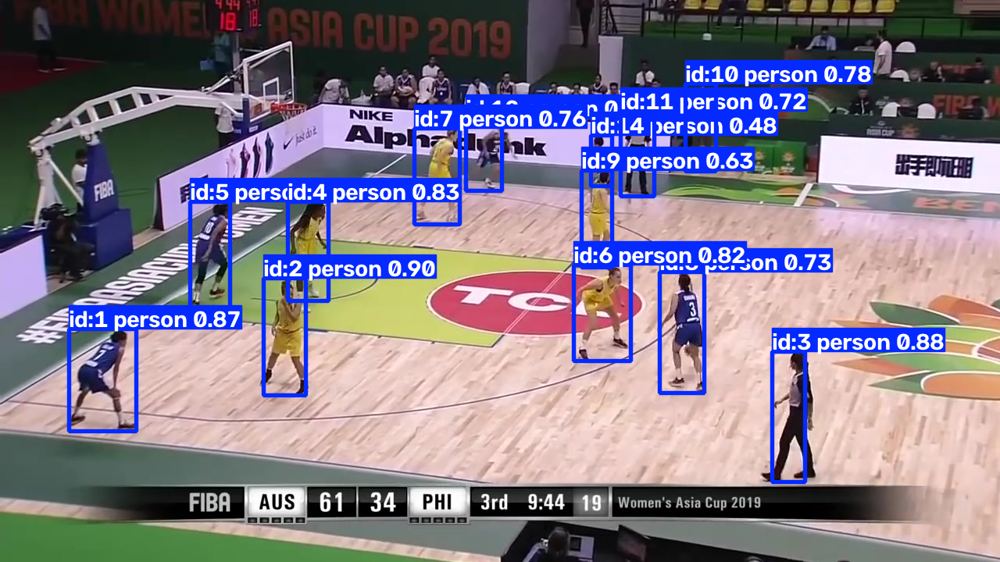

In [16]:
annotated_auto[3]

### Measure it against SportsMOT ground truth
Ground truth only labels players, so this gives a real number for the referee/spectator problem instead of eyeballing it. Compares no filter, your hand-drawn polygon, and the automatic regions.

In [17]:
import io
with tarfile.open(archive, "r") as tar:
    gt = np.loadtxt(io.BytesIO(tar.extractfile(f"{sequence}/gt/gt.txt").read()), delimiter=",")

gt_by_frame = [[(r[2], r[3], r[2]+r[4], r[3]+r[5]) for r in gt[gt[:, 0] == f]]
               for f in range(1, len(frames) + 1)]

def iou(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2-ix1) * max(0, iy2-iy1)
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union else 0

def match(pred, gtb, thr=0.5):
    pairs = sorted(((iou(p, g), i, j) for i, p in enumerate(pred) for j, g in enumerate(gtb)), reverse=True)
    up, ug, tp = set(), set(), 0
    for s, i, j in pairs:
        if s < thr: break
        if i in up or j in ug: continue
        up.add(i); ug.add(j); tp += 1
    return tp, len(pred)-tp, len(gtb)-tp

def pr(pred_per_frame):
    tp = fp = fn = 0
    for p, g in zip(pred_per_frame, gt_by_frame):
        a, b, c = match(p, g); tp += a; fp += b; fn += c
    return tp/(tp+fp) if tp+fp else 0, tp/(tp+fn) if tp+fn else 0

det = YOLO("yolov8m.pt")
raw = [[tuple(b.tolist()) for b in det.predict(f, classes=[0], conf=0.5, verbose=False)[0].boxes.xyxy.cpu().numpy()]
       for f in frames]
hand = [[b for b in boxes if on_court(b)] for boxes in raw]
auto = [[b for b in boxes if box_in_regions(b, regs)] for boxes, regs in zip(raw, court_regions_by_frame)]

for label, preds in [("no filter", raw), ("hand-drawn polygon", hand), ("auto regions", auto)]:
    p, r = pr(preds)
    print(f"{label:<20} precision={p:.3f} recall={r:.3f}")

no filter            precision=0.709 recall=0.840
hand-drawn polygon   precision=0.781 recall=0.840
auto regions         precision=0.727 recall=0.840
